<a href="https://colab.research.google.com/github/Stormbreaker06/EDA/blob/main/Assignment/Accredian_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [156]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


Step - 1

Here i will first try to understand the dataset , the type of data that i am working with.

In [157]:
data = pd.read_csv("instructor_effectiveness_dataset_2000_rows.csv")
print(data.head(5))
data.info()
data.describe()

  batch_id instructor_id course_id  completion_rate  avg_score_improvement  \
0   B_1861         I_044      C_01         0.300000              14.225955   
1   B_0354         I_119      C_06         0.657220              22.871110   
2   B_1334         I_050      C_03         0.300000              16.087517   
3   B_0906         I_024      C_21         0.639507              24.260687   
4   B_1290         I_001      C_08         0.527302              31.081556   

   avg_quiz_score  dropout_rate  avg_watch_time  assignment_submission_rate  \
0       73.546528      0.647423        0.774572                    0.790918   
1       77.312331      0.425098        0.494936                    0.998566   
2       79.563687      0.700000        0.977901                    0.807298   
3       99.295316      0.334657        0.846515                    0.544555   
4       99.393425      0.521099        0.917450                    0.865885   

   forum_activity_rate  avg_feedback_score  feedback_res

,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.602808,27.035844,77.956126,0.394883,0.776515,0.753188,0.250300,4.207134,0.736519
std,0.159667,5.716641,10.695618,0.162747,0.145231,0.148058,0.100640,0.419209,0.149412
min,0.300000,6.159240,40.386725,0.020000,0.287440,0.251111,0.000000,2.639915,0.259935
25%,0.489260,23.124673,70.897590,0.280035,0.675076,0.652110,0.179845,3.918986,0.633293
50%,0.603091,26.938629,78.020567,0.394820,0.780330,0.756380,0.249771,4.205989,0.737213
75%,0.712797,30.885600,85.444286,0.511432,0.894242,0.856458,0.319204,4.503437,0.845876
max,0.980000,40.000000,100.000000,0.700000,1.000000,1.000000,0.641111,5.000000,1.000000


Given dataset has no null values and has only numerical data tyes, consisting of 2000 rows and 12 columns.

Now let's try to visualise the data and gain some insights out of it.

In [158]:
print(data.columns)

Index(['batch_id', 'instructor_id', 'course_id', 'completion_rate',
       'avg_score_improvement', 'avg_quiz_score', 'dropout_rate',
       'avg_watch_time', 'assignment_submission_rate', 'forum_activity_rate',
       'avg_feedback_score', 'feedback_response_rate'],
      dtype='object')


In [159]:
df = pd.DataFrame(data)
instructors = df['instructor_id'].unique()
courses = df['course_id'].unique()
print(len(instructors))
print(len(courses))


120
25


There are 120 instructors teaching 25 courses.

I didn't find any particular column which needed independent analysis ,i find the instructor or course relationship will yeild a better result and understanding rather than just the particular column data. In combination with either above mentioned column will answer more questions of how and why.

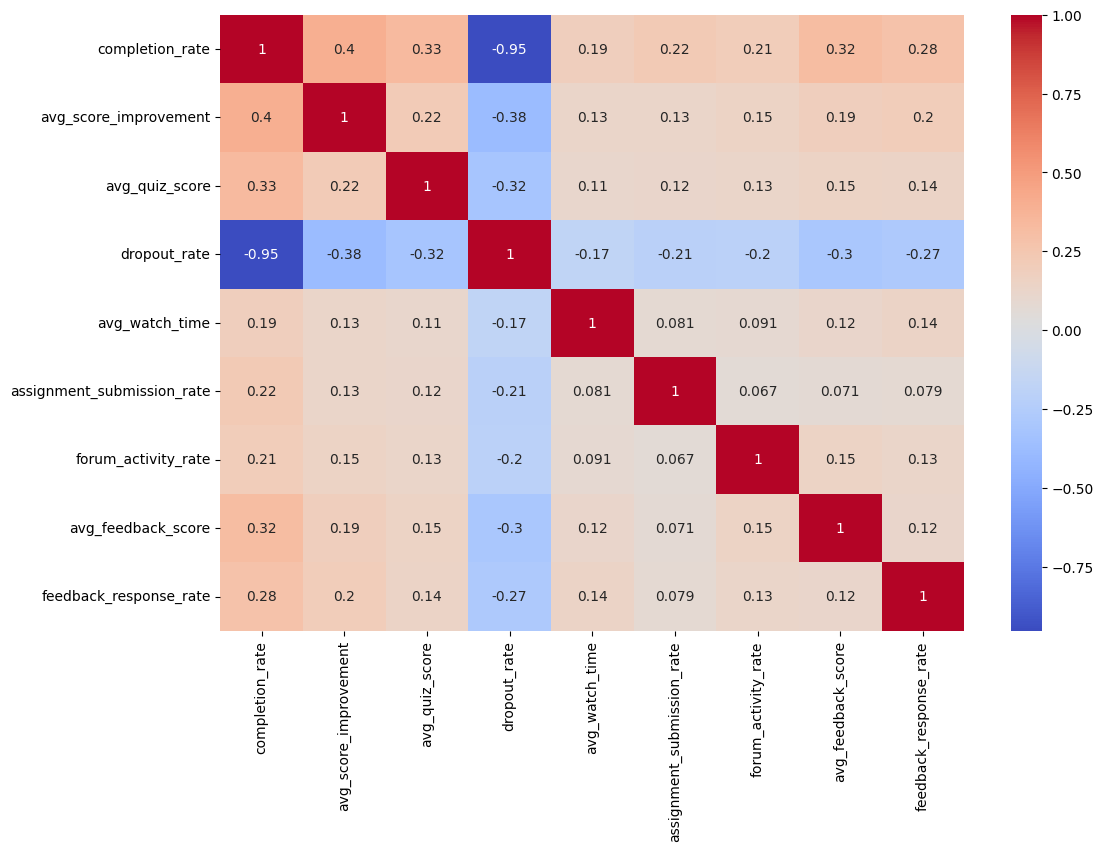

In [160]:
plt.figure(figsize=(12,8))
sns.heatmap(df.select_dtypes('number').corr(),
            annot=True, cmap='coolwarm')
plt.show()

Here i mainly wanted to find relation of completion_rate and dropout_rate with other columns. I had assumed the assignment_submission_rate,avg_quiz_score ,avg_watch_time ,all would be highly related to the above two mentioned columns , but it was not such . Might be cause data is generated or feels like it. avg_watch_time does not seem to be related to avg_score_improvement,avg_quiz_score,assignment_submission_rate either.

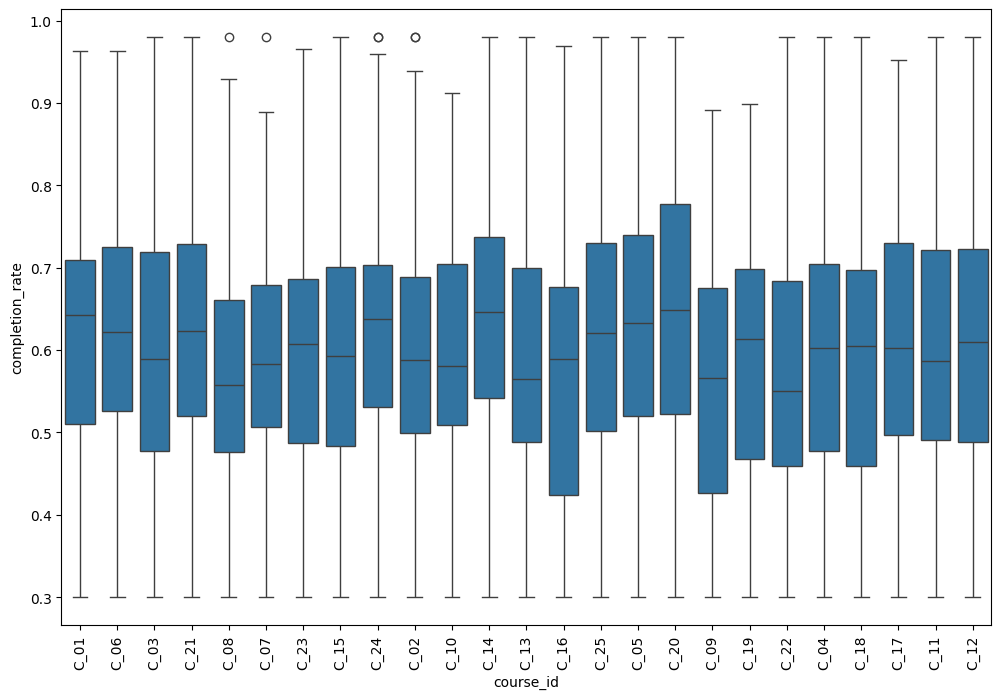

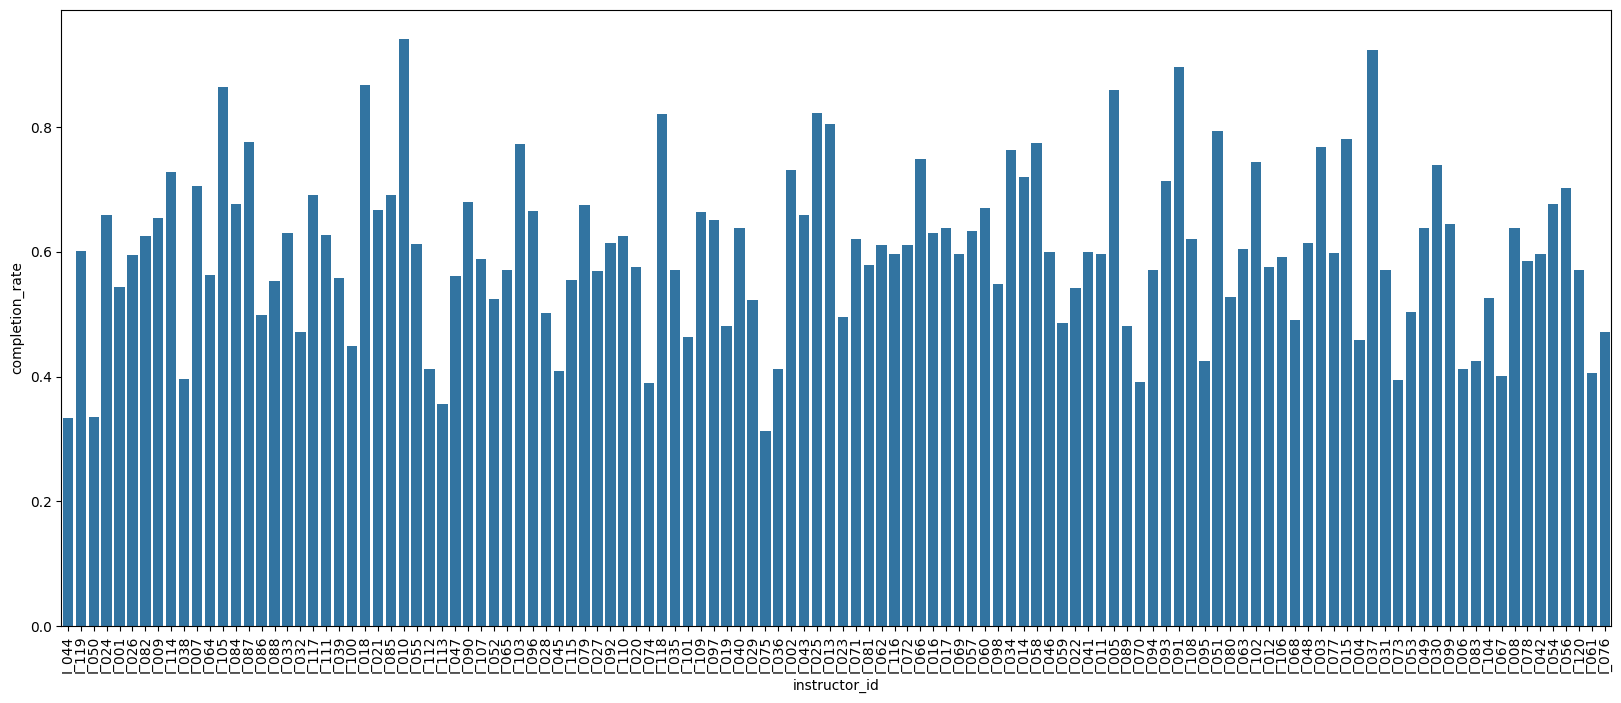

In [161]:
from os import error
plt.figure(figsize=(12,8))
sns.boxplot(data=df, x='course_id',
            y='completion_rate',
            )
plt.xticks(rotation=90)
plt.show()
plt.figure(figsize=(20,8))
sns.barplot(data=df, x='instructor_id',
            y='completion_rate',
            errorbar=None)
plt.xticks(rotation=90)
plt.show()

This does not conclude what effects the completion rate more. Is it the course difficulty or the instructor.

Trying to understand the course difficult levels.

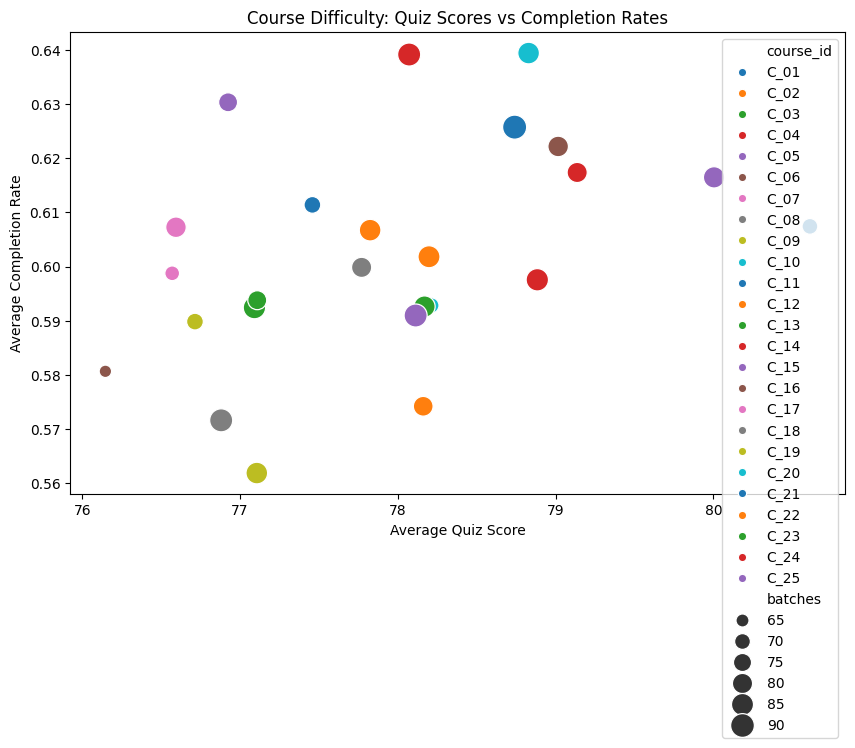

In [162]:
course_analysis = df.groupby('course_id').agg(
    avg_quiz_score=('avg_quiz_score', 'mean'),
    avg_completion_rate=('completion_rate', 'mean'),
    avg_dropout_rate=('dropout_rate', 'mean'),
    batches=('batch_id', 'nunique')
).reset_index()

# print(course_analysis)
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=course_analysis,
    x='avg_quiz_score',
    y='avg_completion_rate',
    hue='course_id',
    size='batches',
    sizes=(80, 300),
    palette='tab10'
)

plt.title('Course Difficulty: Quiz Scores vs Completion Rates')
plt.xlabel('Average Quiz Score')
plt.ylabel('Average Completion Rate')
plt.show()

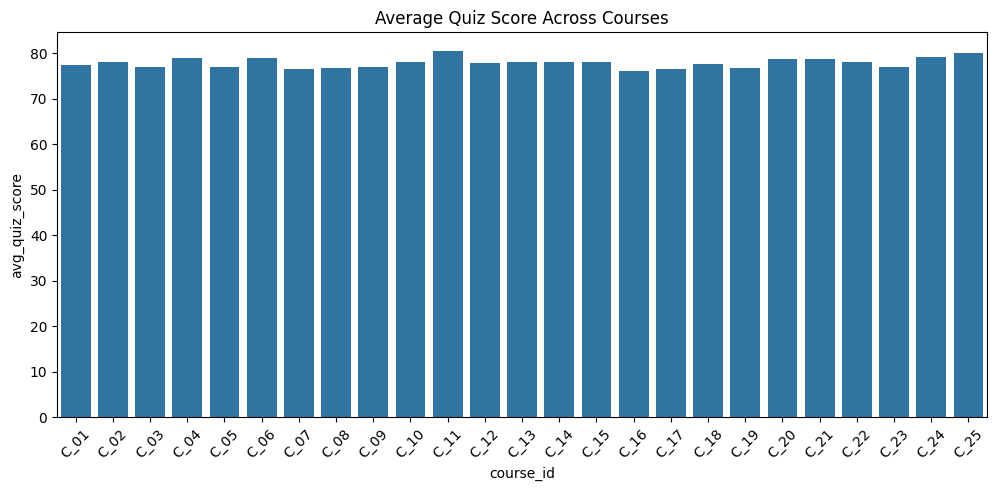

In [163]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=course_analysis,
    x='course_id',
    y='avg_quiz_score',
    errorbar=None
)

plt.title('Average Quiz Score Across Courses')
plt.xticks(rotation=45)
plt.show()

All the courses seems to have the almost the same difficulty rate (as seen by the avg_score) and hence do not effect the completion rate much.

Lets try to understand an instructors working .

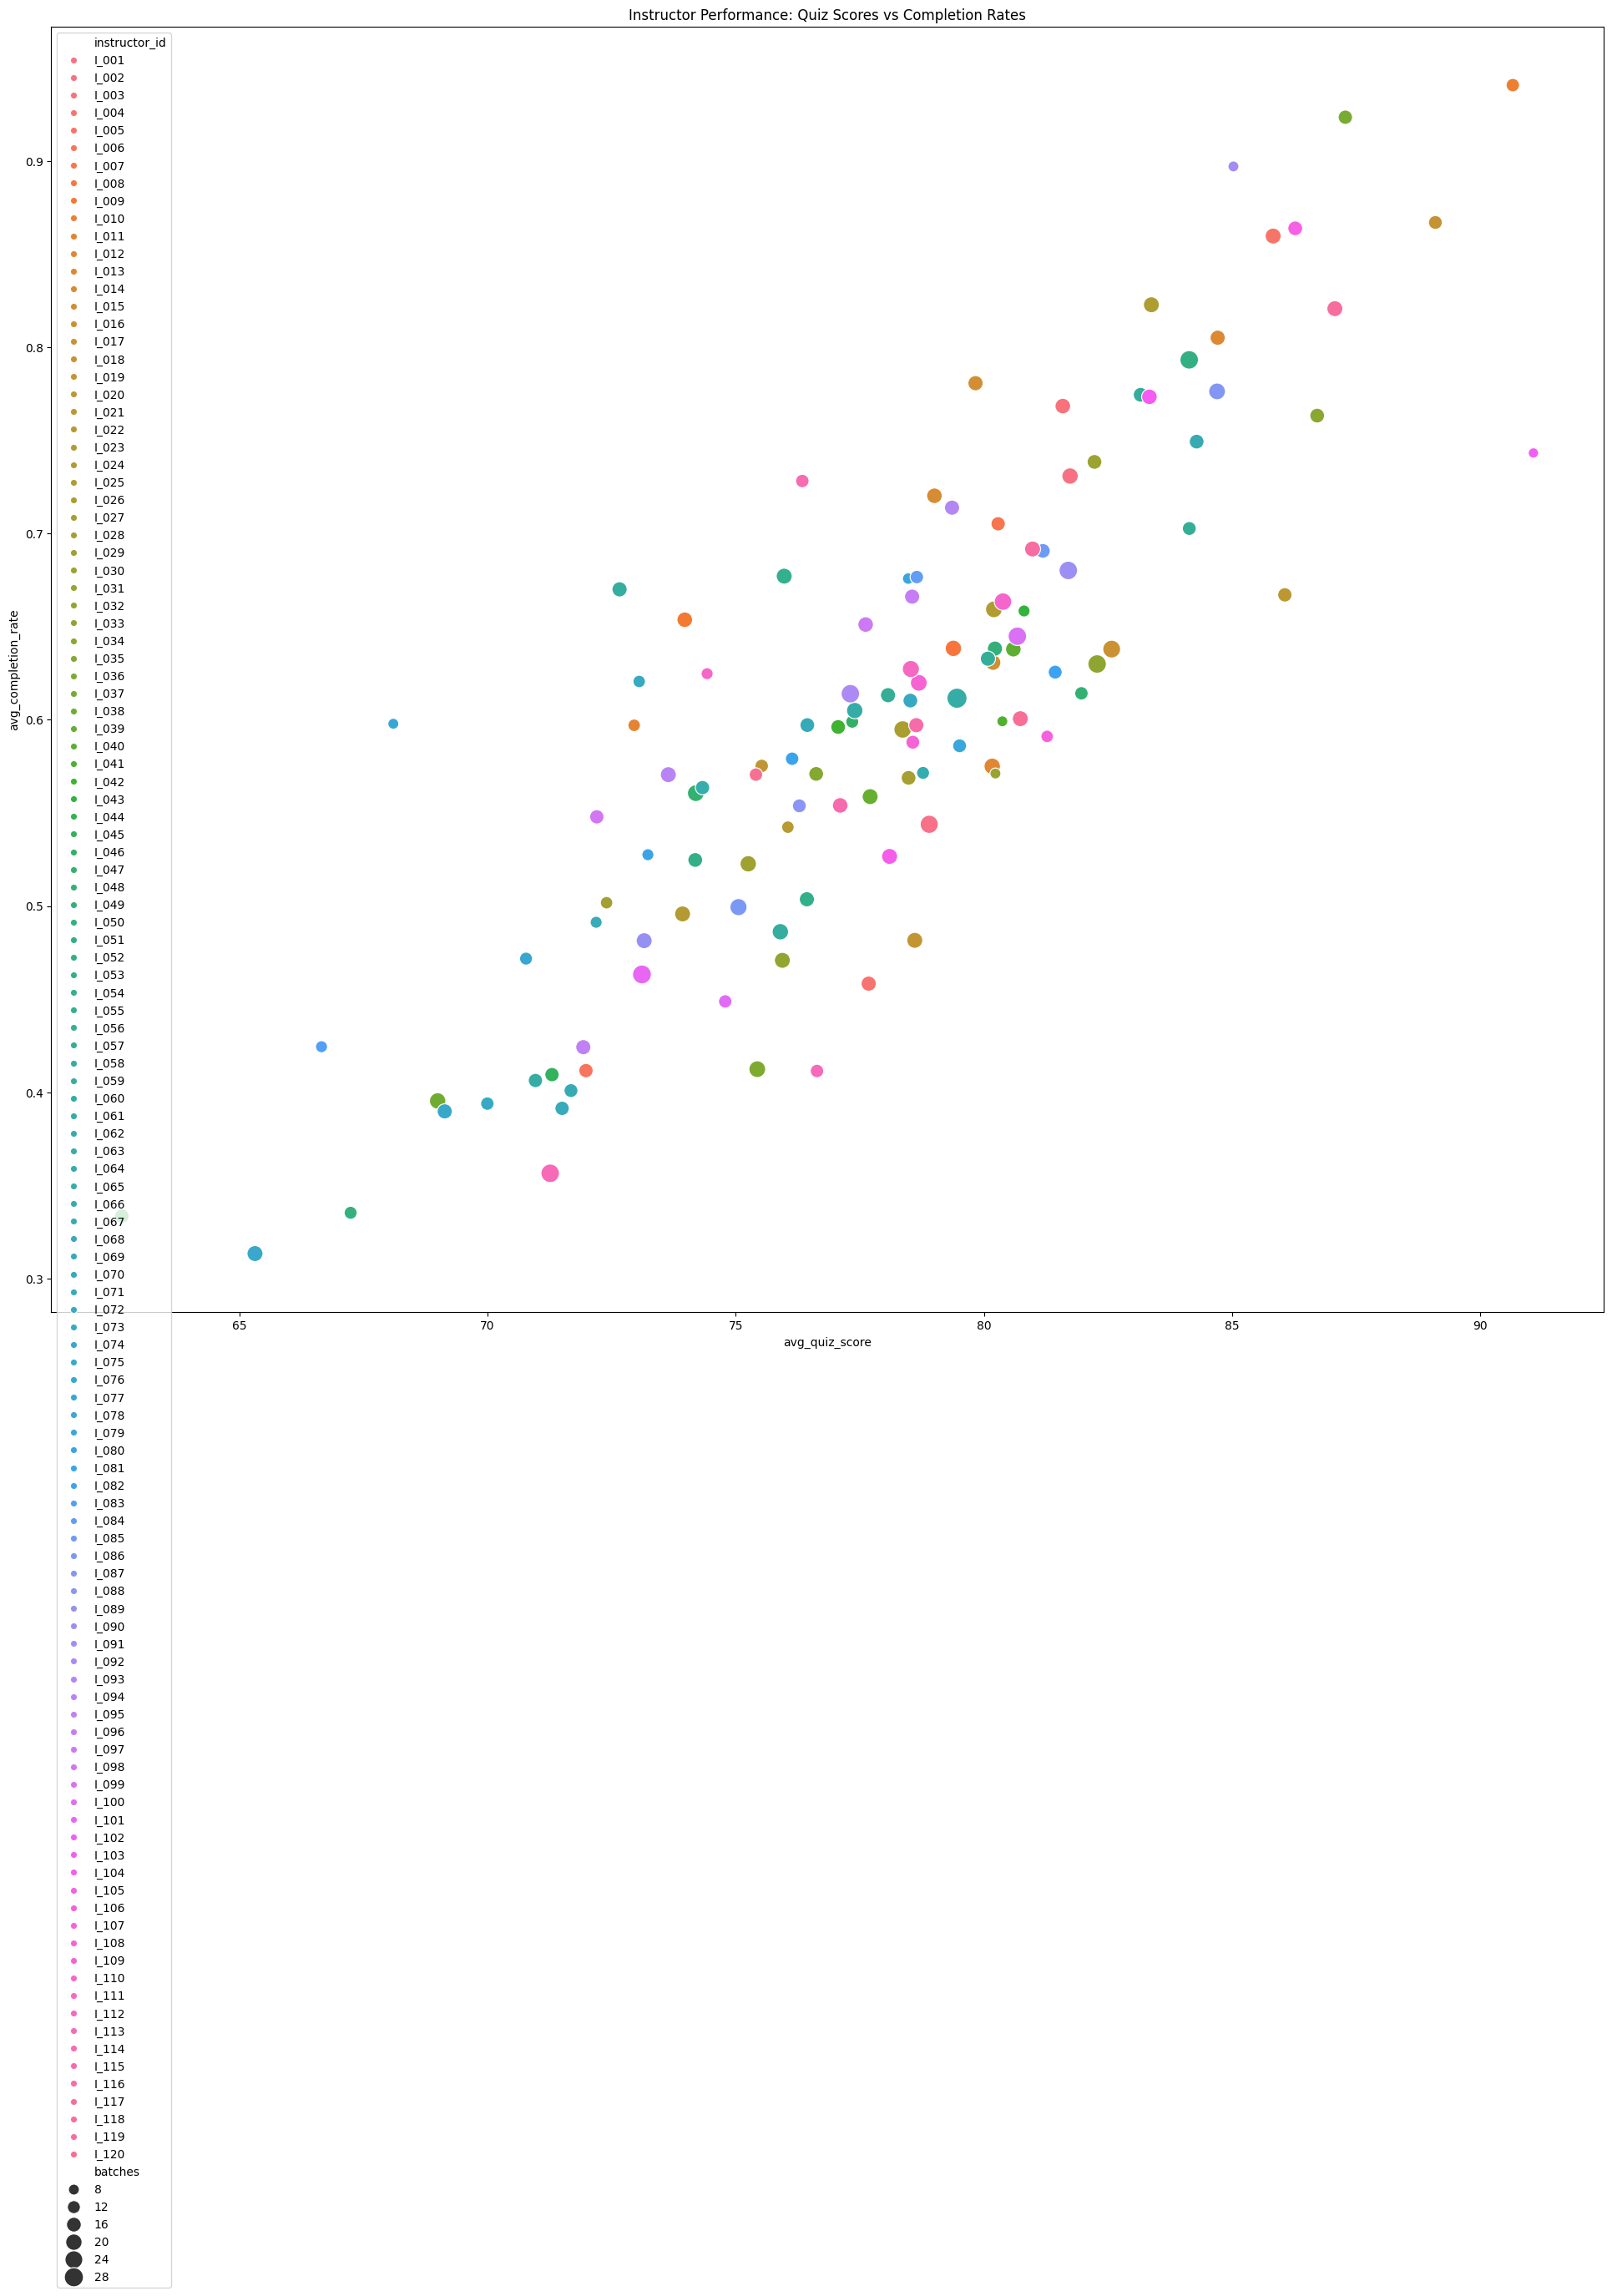

In [164]:
instructor_analysis = df.groupby('instructor_id').agg(
    avg_quiz_score=('avg_quiz_score', 'mean'),
    avg_completion_rate=('completion_rate', 'mean'),
    avg_dropout_rate=('dropout_rate', 'mean'),
    courses=('course_id', 'nunique'),
    batches=('batch_id', 'nunique')
).reset_index()

# print(instructor_analysis)
plt.figure(figsize=(24, 20))

sns.scatterplot(
    data=instructor_analysis,
    x='avg_quiz_score',
    y='avg_completion_rate',
    hue='instructor_id',
    size='batches',
    sizes=(80, 300)
)

plt.title('Instructor Performance: Quiz Scores vs Completion Rates')
plt.show()

This gives us a better understanding , here we can notice certain instructors having lower avg_score as well as lower completion rate, higher avg_score as well as having higher completion rate. This clearly indicates lower or sub par perfomance by an instructor . I plan on using completion rate , avg_quiz_score, avg_score_improvement,avg_watch_time,avg_feedback_score to grade the instructor and get the instructor effectiveness score.

Trying to confirm my assumption of instructor effecting the avg_score and completion rate.

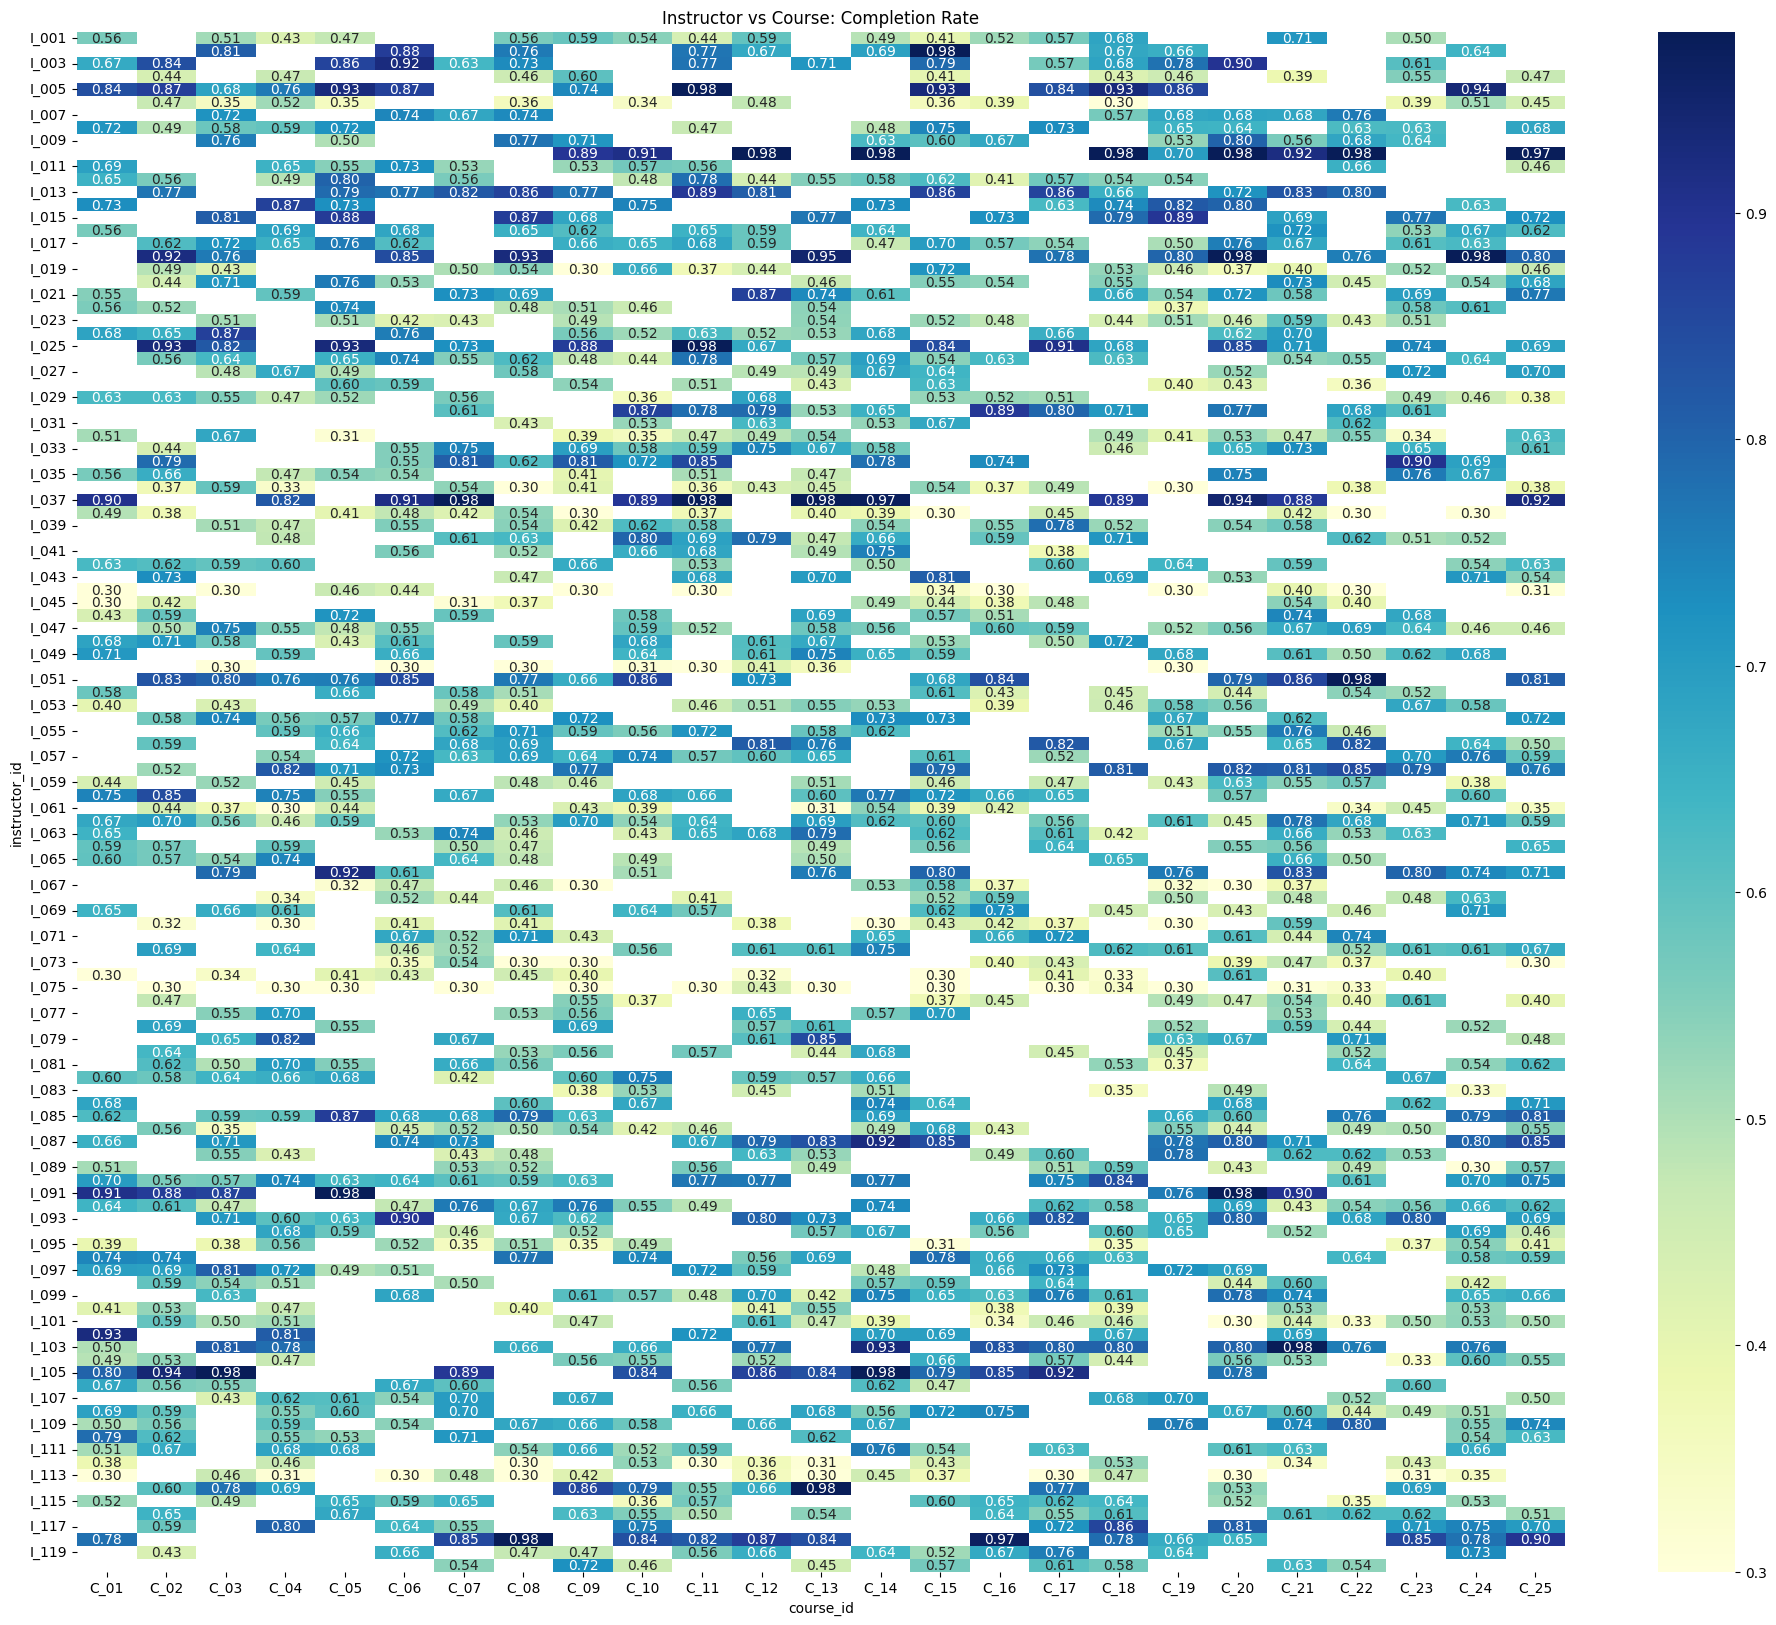

In [165]:
instructor_course = df.groupby(
    ['course_id', 'instructor_id']
).agg(
    avg_quiz_score=('avg_quiz_score', 'mean'),
    completion_rate=('completion_rate', 'mean'),
    dropout_rate=('dropout_rate', 'mean'),
    batches=('batch_id', 'nunique')
).reset_index()

# print(instructor_course)
plt.figure(figsize=(24, 20))

pivot = instructor_course.pivot(
    index='instructor_id',
    columns='course_id',
    values='completion_rate'
)

sns.heatmap(pivot, annot=True, cmap='YlGnBu',
            fmt='.2f')

plt.title('Instructor vs Course: Completion Rate')
plt.show()

In [166]:
instructor_overall = instructor_course.groupby('instructor_id').agg(
    avg_completion_rate=('completion_rate', 'mean'),
    avg_quiz_score=('avg_quiz_score', 'mean'),
    avg_dropout_rate=('dropout_rate', 'mean'),
    total_courses=('course_id', 'nunique'),
    total_batches=('batches', 'sum')
).reset_index()

instructor_overall = instructor_overall.sort_values(
    'avg_completion_rate'
)

instructor_overall.head(10)

,instructor_id,avg_completion_rate,avg_quiz_score,avg_dropout_rate,total_courses,total_batches
74,I_075,0.315067,66.192714,0.660754,14,19
49,I_050,0.323624,66.434261,0.667747,8,12
43,I_044,0.337763,63.796996,0.611736,12,15
112,I_113,0.362208,70.965552,0.618588,16,26
72,I_073,0.385406,69.483676,0.595292,10,13
69,I_070,0.385671,73.403315,0.614647,11,15
73,I_074,0.390887,69.185579,0.611776,12,17
37,I_038,0.395835,69.182543,0.604031,15,20
111,I_112,0.398889,77.065384,0.596003,11,13
60,I_061,0.399228,70.620142,0.608746,13,15


The above two (heat map and avg of our metrice) confirms our assumtion of instructor effecting the other rates.

Step - 2

Lets now try to score the instructor , hence develop the  "Instructor Effectiveness Score" , IES for short.

In [167]:
metrics = [
    'completion_rate',
    'avg_quiz_score',
    'avg_score_improvement',
    'avg_watch_time',
    'avg_feedback_score'
]
instructor_df = df.groupby('instructor_id')[metrics].mean().reset_index()
instructor_df.head()

,instructor_id,completion_rate,avg_quiz_score,avg_score_improvement,avg_watch_time,avg_feedback_score
0,I_001,0.543887,78.900194,26.641462,0.766513,4.217743
1,I_002,0.730874,81.737198,30.166242,0.837393,4.343002
2,I_003,0.768447,81.590928,29.977813,0.818441,4.450034
3,I_004,0.458328,77.680317,22.912021,0.793130,4.076410
4,I_005,0.859747,85.828159,32.588652,0.847026,4.202516


here i am using the above five things that i belive are affected by the instructor effectiveness / perfomance.

function to categorise the IES based on score.

In [168]:
def categorize_ies(score):
    if score < 50:
        return 'Low'
    elif score < 75:
        return 'Moderate'
    else:
        return 'High'

In [169]:
from sklearn.preprocessing import MinMaxScaler

weights = {
    'completion_rate': 0.25,
    'avg_quiz_score': 0.30,
    'avg_score_improvement': 0.25,
    'avg_watch_time': 0.10,
    'avg_feedback_score': 0.10
}

scaler = MinMaxScaler()

instructor_df[metrics] = scaler.fit_transform(
    instructor_df[metrics]
)
# print(instructor_df.head())
instructor_df['IES'] = sum(
    instructor_df[col] * weight
    for col, weight in weights.items()
) * 100

instructor_df = instructor_df.sort_values(
    'IES', ascending=False
)


instructor_df['IES_Category'] = instructor_df['IES'].apply(categorize_ies)
print(instructor_df[['instructor_id', 'IES_Category']])
# for i in range(len(instructor_df)):
#     print(f"{instructor_df.iloc[i]['instructor_id']} | {instructor_df.iloc[i]['IES']}")

    instructor_id IES_Category
9           I_010         High
36          I_037         High
17          I_018         High
104         I_105         High
90          I_091         High
..            ...          ...
44          I_045          Low
112         I_113          Low
49          I_050          Low
74          I_075          Low
43          I_044          Low

[120 rows x 2 columns]


Here there are multiple things which i have done. As there was no predefined formula i sort of created something by giving weights to each column, I have highly ranked avg_quiz_score,avg_score_imprtovement and completion rate. I have given little importance to the feedback_score and watch_time. I belive at the end of the day a student completing the course with a good improvement and score matter mores than watch_time or their feedback , hence i have given the weights accordingly.I named the score IES, that is Instructor Efficiency Score.

Lets try to visualise the distribution of instructor based on the newly IES_Category (Low,Moderate,High) allocated to them.

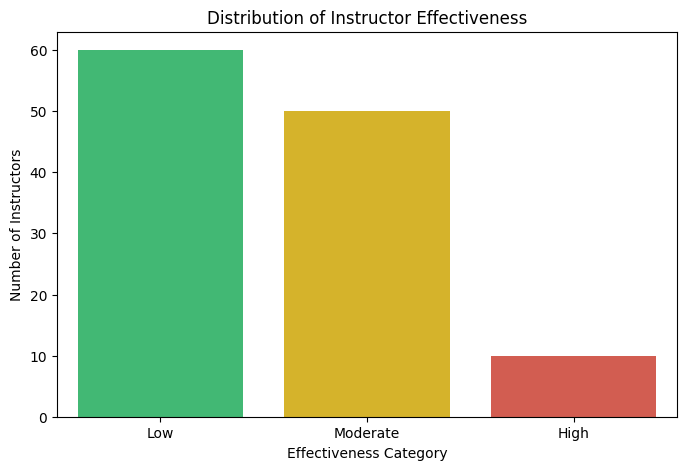

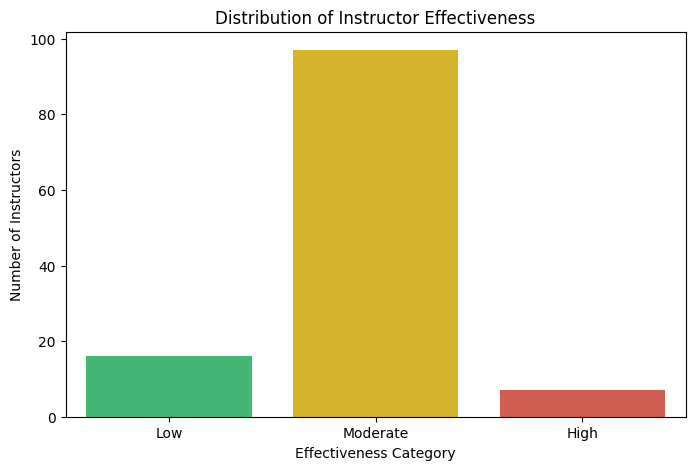

In [170]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=instructor_df,
    x='IES_Category',
    order=['Low', 'Moderate', 'High'],
    hue='IES_Category',
    palette=['#e74c3c', '#f1c40f', '#2ecc71'],
    legend=False
)

plt.title('Distribution of Instructor Effectiveness')
plt.xlabel('Effectiveness Category')
plt.ylabel('Number of Instructors')
plt.show()
def categorize_ies(score):
    if score < 30:
        return 'Low'
    elif score < 80:
        return 'Moderate'
    else:
        return 'High'
instructor_df['IES_Category'] = instructor_df['IES'].apply(categorize_ies)
# print(instructor_df[['instructor_id', 'IES_Category']])
plt.figure(figsize=(8, 5))

sns.countplot(
    data=instructor_df,
    x='IES_Category',
    order=['Low', 'Moderate', 'High'],
    hue='IES_Category',
    palette=['#e74c3c', '#f1c40f', '#2ecc71'],
    legend=False
)

plt.title('Distribution of Instructor Effectiveness')
plt.xlabel('Effectiveness Category')
plt.ylabel('Number of Instructors')
plt.show()

Due to me giving the cutoff score as 50 and 75 , the count seems to have come this way (skewed).Further updating it gives us a normal distribution , that is extermes are less and the average is more. This is more to my expectations.

Step - 3

 Aggregating Batch Data to Instructor Level, i am going with mean as my aggregating function.


In [171]:
metrics = [
    'completion_rate',
    'avg_score_improvement',
    'avg_quiz_score',
    'dropout_rate',
    'avg_watch_time',
    'assignment_submission_rate',
    'forum_activity_rate',
    'avg_feedback_score',
    'feedback_response_rate'
]

instructor_df_agg = df.groupby('instructor_id').agg(
    **{
        f'{col}_mean': (col, 'mean')
        for col in metrics
    },
    **{
        f'{col}_std': (col, 'std')
        for col in metrics
    },
    total_batches=('batch_id', 'nunique'),
    total_courses=('course_id', 'nunique')
).reset_index()

batches_per_instructor = df.groupby('instructor_id')['batch_id'].nunique()
avg_batches = batches_per_instructor.mean()
# print("Average batches per instructor:", avg_batches)

instructor_df_agg['data_confidence'] = instructor_df_agg['total_batches'].apply(
    lambda x: 'High' if x > 16 else
              'Moderate' if x > 8 else
              'Low'
)
instructor_df_agg.head()

,instructor_id,completion_rate_mean,avg_score_improvement_mean,avg_quiz_score_mean,dropout_rate_mean,avg_watch_time_mean,assignment_submission_rate_mean,forum_activity_rate_mean,avg_feedback_score_mean,feedback_response_rate_mean,...,avg_quiz_score_std,dropout_rate_std,avg_watch_time_std,assignment_submission_rate_std,forum_activity_rate_std,avg_feedback_score_std,feedback_response_rate_std,total_batches,total_courses,data_confidence
0,I_001,0.543887,26.641462,78.900194,0.470593,0.766513,0.726893,0.240551,4.217743,0.694858,...,8.878089,0.087671,0.131532,0.145189,0.094695,0.388802,0.166455,25,16,High
1,I_002,0.730874,30.166242,81.737198,0.247194,0.837393,0.774394,0.289610,4.343002,0.784338,...,9.843168,0.098811,0.112701,0.141096,0.088573,0.440235,0.114460,20,10,High
2,I_003,0.768447,29.977813,81.590928,0.234828,0.818441,0.779606,0.296224,4.450034,0.812132,...,11.064673,0.115966,0.158280,0.121712,0.082414,0.386108,0.141805,18,14,High
3,I_004,0.458328,22.912021,77.680317,0.547261,0.793130,0.758317,0.226259,4.076410,0.721460,...,12.485520,0.083598,0.126603,0.135790,0.093217,0.400982,0.133622,17,10,High
4,I_005,0.859747,32.588652,85.828159,0.145733,0.847026,0.876942,0.333519,4.202516,0.784197,...,7.228742,0.097634,0.108567,0.102360,0.105278,0.304174,0.127054,19,13,High


Here instrutors with few batches are quite tricky .Instructors with high numer of batches the data can confidently speak for it. I categorised them by data confidence , how confident i am on that particular instructor's IES score (Instructor Eficiency Score) based on the number of batches they have taken . Mainly the number 16 is by the average number of batches an instructor takes (It is 16.66), and half of it 8 seems to be a good point for the moderate confidence.
I used mean as aggregating function in all the columns as it made the most sense if i wanted to asses an instructor .I also introduced standard deviation to check if the data was not much varying. Similar to how you would asses a student by checking his average score across subjects not just median score, this decision made sense to me.

Adding the IES_Category as i will be further using it in the next step

In [172]:
instructor_df_agg['IES_Category'] = instructor_df['IES_Category']
instructor_df_agg.head()
# print(instructor_df_agg.columns)

,instructor_id,completion_rate_mean,avg_score_improvement_mean,avg_quiz_score_mean,dropout_rate_mean,avg_watch_time_mean,assignment_submission_rate_mean,forum_activity_rate_mean,avg_feedback_score_mean,feedback_response_rate_mean,...,dropout_rate_std,avg_watch_time_std,assignment_submission_rate_std,forum_activity_rate_std,avg_feedback_score_std,feedback_response_rate_std,total_batches,total_courses,data_confidence,IES_Category
0,I_001,0.543887,26.641462,78.900194,0.470593,0.766513,0.726893,0.240551,4.217743,0.694858,...,0.087671,0.131532,0.145189,0.094695,0.388802,0.166455,25,16,High,Moderate
1,I_002,0.730874,30.166242,81.737198,0.247194,0.837393,0.774394,0.289610,4.343002,0.784338,...,0.098811,0.112701,0.141096,0.088573,0.440235,0.114460,20,10,High,Moderate
2,I_003,0.768447,29.977813,81.590928,0.234828,0.818441,0.779606,0.296224,4.450034,0.812132,...,0.115966,0.158280,0.121712,0.082414,0.386108,0.141805,18,14,High,Moderate
3,I_004,0.458328,22.912021,77.680317,0.547261,0.793130,0.758317,0.226259,4.076410,0.721460,...,0.083598,0.126603,0.135790,0.093217,0.400982,0.133622,17,10,High,Moderate
4,I_005,0.859747,32.588652,85.828159,0.145733,0.847026,0.876942,0.333519,4.202516,0.784197,...,0.097634,0.108567,0.102360,0.105278,0.304174,0.127054,19,13,High,High


Step - 4

Trying to build a machine learning model

In [173]:
from sklearn.model_selection import train_test_split

features = [
    'completion_rate_mean',
    'avg_score_improvement_mean',
    'avg_quiz_score_mean',
    'avg_watch_time_mean',
    'avg_feedback_score_mean',
    'dropout_rate_mean',
    'assignment_submission_rate_mean',
    'forum_activity_rate_mean',
    'feedback_response_rate_mean',
    'total_batches',
    'total_courses',
    'completion_rate_std',
    'avg_quiz_score_std'
]

X = instructor_df_agg[features]
y = instructor_df_agg['IES_Category']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Checking the data split

In [174]:
print(y.value_counts())
print(y_train.value_counts())
print(y_test.value_counts())

IES_Category
Moderate    97
Low         16
High         7
Name: count, dtype: int64
IES_Category
Moderate    77
Low         13
High         6
Name: count, dtype: int64
IES_Category
Moderate    20
Low          3
High         1
Name: count, dtype: int64


The high and low data split are not ideal.

In [175]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

I choose Decison Tree Classifier as the target IES_Category has three classes (Low,Moderate,High), easy to interpret which metrice influences the most, it can capture non-linear relations,feature scaling is not required.


Step - 5

Evaluating the Model

In [176]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))



Accuracy: 0.875

Classification Report:
              precision    recall  f1-score   support

        High       0.00      0.00      0.00         1
         Low       0.75      1.00      0.86         3
    Moderate       0.95      0.90      0.92        20

    accuracy                           0.88        24
   macro avg       0.57      0.63      0.59        24
weighted avg       0.88      0.88      0.88        24



Overall the model accuracy seems to be 87.5%.
"High" - Not having much data in training ,the lower precision ,recall seems to be understandable. There is also only 1 case in the test dataset .
"Low" - all the "low" points in the dataset have been identified , this is great . It also identifies with a good precision. But again there were only 3 to identify
"Moderate" - It has a precision of 0.95 which is great and recall of 0.90 , this is the best of the three.
There is a significant class imbalance here. I gave "Moderate" the most space (30-80), which seems to have effected the results.
Here one thing is good that the low recall is 1 , which means if we once identify all "Low" instructors we are sure that the low instructor is present in our collection.
With high precisions we do not need to worry significantly about wrong decision making .

Step - 6

Interpreting the Results

                            Feature  Importance
2               avg_quiz_score_mean    0.614965
5                 dropout_rate_mean    0.353709
0              completion_rate_mean    0.031326
3               avg_watch_time_mean    0.000000
1        avg_score_improvement_mean    0.000000
4           avg_feedback_score_mean    0.000000
6   assignment_submission_rate_mean    0.000000
7          forum_activity_rate_mean    0.000000
8       feedback_response_rate_mean    0.000000
9                     total_batches    0.000000
10                    total_courses    0.000000
11              completion_rate_std    0.000000
12               avg_quiz_score_std    0.000000


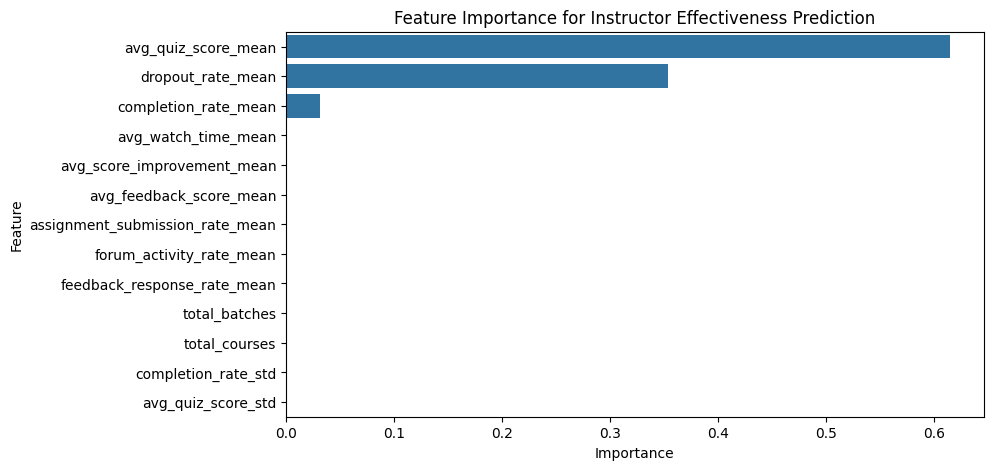

In [177]:
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

print(importance_df)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance for Instructor Effectiveness Prediction')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

From the Decision Tree Classifier we get avg_score_quiz_mean as the highest influencer of the classification .Followed by dropout_rate_mean, this comes to me as a shock , i did not expect it to be higher than completion_rate_mean. This indicates that the formula should be changed and made better , more research and thought needs to be put in weights and the selection process. The IES score hence generated should be taken with a pinch of salt and not to be considered the final conclusion for an instructor.Rest of the features also show very low importance ,total_batches , total_courses, the standard_deviations, feedback response_rate_mean, forum_activity_mean .Having lower importance rate is justifiable , they do not effect the instructors teaching. Rest should have some effect/importance.

Results which we obtain from the above classification model. If we solely go on the numbers we are getting good results, we have higher precison and recalls , all of them combined help us really well identify an instructors class (IES_Category ,low,moderate,high). But we can not solely rely on them . One more key issue here is as discussed we could not conclude the correctness of my formula hence the model might not have been trained on accurate data . Another thing of importance is the dataset does not mention the size of batches , are all batches the same . Batch size might effect the instructor perfomance.   

Which features most influenced instructor effectiveness, and why?
ans - avg_quiz_score_mean had the highest influence on the instructor effectivness . This makes sense to me as i had given the avg_quiz_score the highest weight , based on those weights we calculated the IES and based on those we had the categories. Hence i think the highest influencing feature might me due to my bias as such. But i also think this is one of the thing someone would see while evaluating an instructor , so it seems to be in rght place.

Which variables could be misleading or confounded?
ans - I still belive the dropout_rate could be misleading , as droping out is complimentary to completion rate , both should have a similar importance here. Also avg_watch_time_mean and avg_score_improvement_mean seems to be under represented here. avg_watch_time again could be due to my bias and giving it less weightage.

How could this model fail in real-world usage?
ans - As stated earlier there is a class imbalance in the dataset , this could be one of the main reason the classifier fails. Limited training data is also one of the leading reason. The batch size would not be consistent throughout. An instructor could we improve over the time and hence an eary classification might give us a false positive.

What additional data would you want to improve this analysis?
ans - first thing as i had mentioned earlier too , number of student per batch , next thing is tricky but the knowledge level of students in a batch this could also influence an instructor perfomance , a batch of highly capable students will not solely rely on an instructors effectiveness/perfomance. Course difficult, student attendance ,instructor experience,

Should this model be used for instructor performance evaluation? Why or why not?
ans - No, this model should not be solely used for an instructor perfomance evaluation as stated earlier there are too many things the model still does not take care of and also the unreliability of the formula. It can be maybe after further improvement used for preliminary analysis of the instructor but it should not be the sole judgement tool , specially when it comes to promotions , salaries, etc.